Simulate a AT schedule from a trajectory.
- Take in params
- output Simulated AT

Simulate a complete trial. 

In [33]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
from scipy import stats
from pathlib import Path
import shutil
import cmdstanpy
import arviz as az

import matplotlib.pyplot as plt
from at_modelling.LotkaVolterraModel import LotkaVolterraModel
from utils.synth_data import draw_params, complete_param_dict, progress_on_ct, add_cycle_col, plot_n_rand_patients


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Lets call instantiate a lotka volterra model. We can call the paramDic to see what params it has set

In [34]:
np.random.seed(1)

#the model is set with default params
lv_model = LotkaVolterraModel()

print(f'Params:', lv_model.param_dic)
print(f'StateVars', lv_model.state_vars)

lv_model.set_params(rS=1)
lv_model.simulate_at(tumour_size_when_progressed=1.2)
lv_model.ode_df

Params: {'DMax': 1, 'rS': 0.027, 'rR': 0.027, 'K': 1, 'dD': 1.5, 'dS': 0.0, 'dR': 0.0, 'S0': 0.74, 'R0': 0.01, 'sigma': 0}
StateVars ['S', 'R']


,Time,DrugConcentration,S,R,TumourSize
0,0.000,1.0,7.400000e-01,0.010000,0.750000
1,0.001,1.0,7.399075e-01,0.010000,0.749908
2,0.002,1.0,7.398150e-01,0.010000,0.749815
3,0.003,1.0,7.397224e-01,0.010000,0.749723
4,0.004,1.0,7.396298e-01,0.010000,0.749630
...,...,...,...,...,...
996,405.996,1.0,7.460966e-10,0.901840,0.901840
997,405.997,1.0,7.460600e-10,0.901842,0.901842
998,405.998,1.0,7.460234e-10,0.901845,0.901845
999,405.999,1.0,7.459867e-10,0.901847,0.901847


But it wont simulate yet. If you uncomment and run the following block, you should get an error that the model doesn't have an 'initialStateList'

In [35]:
#model_example.simulate_at()

We can set our own initial state list, or simply call the Setparams which will get the values from the param dic (R0, S0). Note that a number of arguments can be passed 

We see that We can the print the results. The default time resolution is very high. We can clean the df to longer intervals and also be sure to remove post progression obs

## part 2
We can use the model simulate an entire trial. We can the use this data to test out inferential pipeline such as a bayesian fitting routine. We can add some makeshift, but the proper way to do it would be flexible model code. 

Soft-prior copy of `genertate_synth_AT_trial_data.ipynb`. The prior on turnover is replaced by a prior on
`u = (1 - turnover / (1 - cost)) / n0`, the size the tumour levels off at on continuous therapy relative to its starting size.
`u > 1.2` means the patient progresses. turnover is computed back as `(1 - cost) * (1 - u * n0)`, and `u` has to be below `1 / n0`.
The data go to `../synth_data_u` and the Stan model is `../stan/model_switchable_u.stan`.

P(u < 1.2): 0.07106048489806771


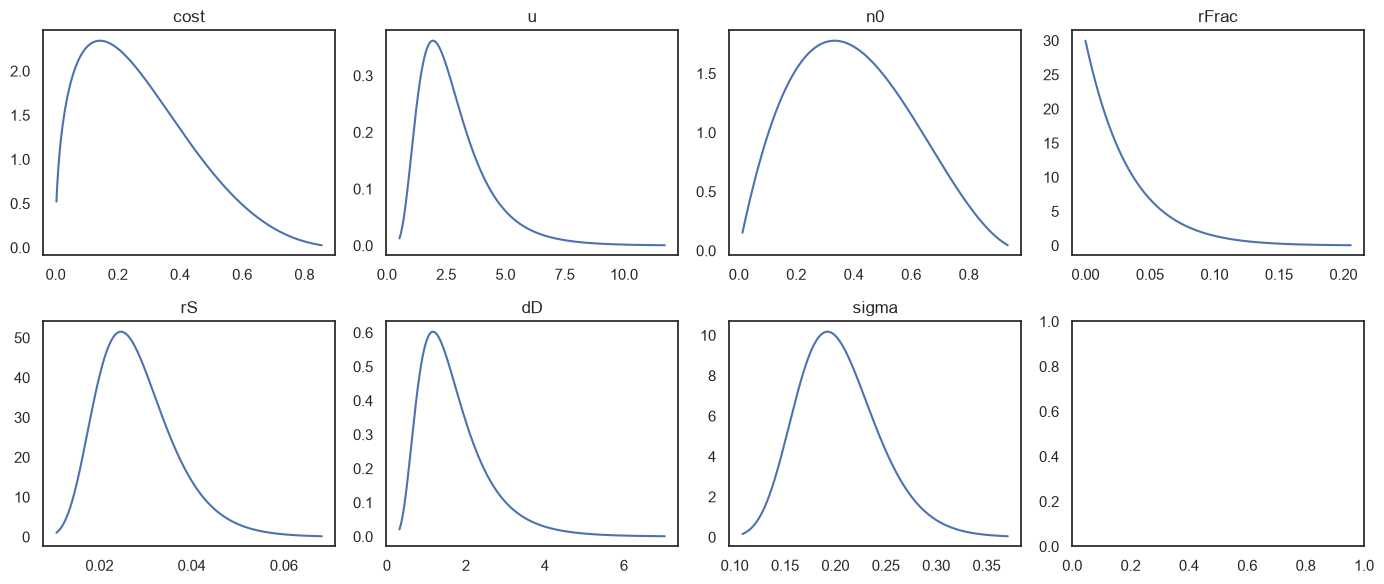

In [36]:
priorDic = {
    "cost":     stats.beta(1.5, 4),                       
    "u":        stats.lognorm(s=0.5, scale=2.5),           
    "n0":       stats.beta(2, 3),
    "rFrac":    stats.beta(1, 30),                    
    "rS":       stats.lognorm(s=0.3, scale=0.027),
    "dD":       stats.lognorm(s=0.5, scale=1.5),
    'sigma':    stats.lognorm(s=.2, scale=.2),
}

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (name, dist) in zip(axes.flat, priorDic.items()):
    x = np.linspace(*dist.ppf([0.001, 0.999]), 400)
    ax.plot(x, dist.pdf(x)); ax.set_title(name)

plt.tight_layout()

#amount of u below 1.2
print('P(u < 1.2):', priorDic["u"].cdf(1.2))

Generate synth patient data

In [37]:
# Generate random patients
n_patients = 10
check_progression = True
t_end = 5000  # Ensure progression occurs in this period

#setup path
out_dir = Path('../synth_data_u')
shutil.rmtree(out_dir, ignore_errors=True) #delete if exists
out_dir.mkdir(parents=True)


#wrap in function and move to stan data file 
#generate synth data
patients, true_params = [], []
for i in range(n_patients):
    #run loop until viable param combination is found
    while True:
        priorDrawDic = draw_params(priorDic)
        if priorDrawDic['u'] * priorDrawDic['n0'] >= 1:
            continue #the plateau can't be above the carrying capacity
        priorDrawDic['turnover'] = (1 - priorDrawDic['cost']) * (1 - priorDrawDic['u'] * priorDrawDic['n0'])
        priorDrawDic['K'] = 1 #hard code carrying cap
        paramDic = complete_param_dict(**{k: v for k, v in priorDrawDic.items() if k != 'u'})
        if not progress_on_ct(paramDic=paramDic):
            print("Analytically doesnt progress CT")
            continue
        model = LotkaVolterraModel(method='RK45', dt=1)
        model.set_params(**{k: v for k, v in paramDic.items() if k not in ("Cost", "Turnover", "n0")})
        model.simulate_at(at_threshold=0.5, interval_length=28, t_end=t_end)
        if not np.isnan(model.ttp) or not check_progression:
            print(f"Check passed or not checking progression on AT! Saving Patient {i} out of {n_patients}")
            break
        print("Check failed")
    #break out while loop and store found param combination. Observation is NaN except at the check-ups
    patients.append(add_cycle_col(model.results_df(), 'DrugConcentration').assign(PatientId=i))
    true_params.append({**priorDrawDic, "PatientId": i})
pd.concat(patients, ignore_index=True).to_csv(out_dir / 'synth_patients.csv', index=False)
pd.DataFrame(true_params).to_csv(out_dir / 'true_params.csv', index=False)

Check passed or not checking progression on AT! Saving Patient 0 out of 10
Check passed or not checking progression on AT! Saving Patient 1 out of 10
Check passed or not checking progression on AT! Saving Patient 2 out of 10
Check passed or not checking progression on AT! Saving Patient 3 out of 10
Check passed or not checking progression on AT! Saving Patient 4 out of 10
Check passed or not checking progression on AT! Saving Patient 5 out of 10
Check passed or not checking progression on AT! Saving Patient 6 out of 10
Check passed or not checking progression on AT! Saving Patient 7 out of 10
Check passed or not checking progression on AT! Saving Patient 8 out of 10
Check passed or not checking progression on AT! Saving Patient 9 out of 10


Lets plot the patients we just generated.

array([[<Axes: title={'center': 'Time'}>,
        <Axes: title={'center': 'Cycle'}>]], dtype=object)

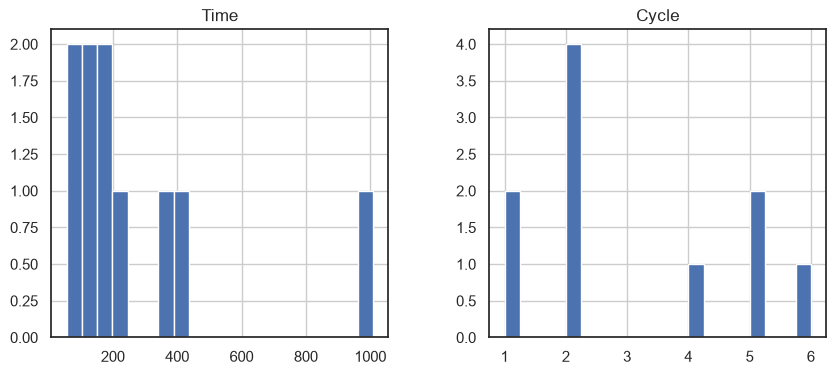

In [38]:
synth_df = pd.read_csv('../synth_data_u/synth_patients.csv')

summary = synth_df.groupby('PatientId').agg({'Time': 'max', 'Cycle': 'max' })
summary.hist(bins=20, figsize=(10, 4))


And we can plot a set of the generated patient trajectories

chain 4:  75%|███████▌  | 1500/2000 [38:22<12:47,  1.54s/it, (Sampling)]


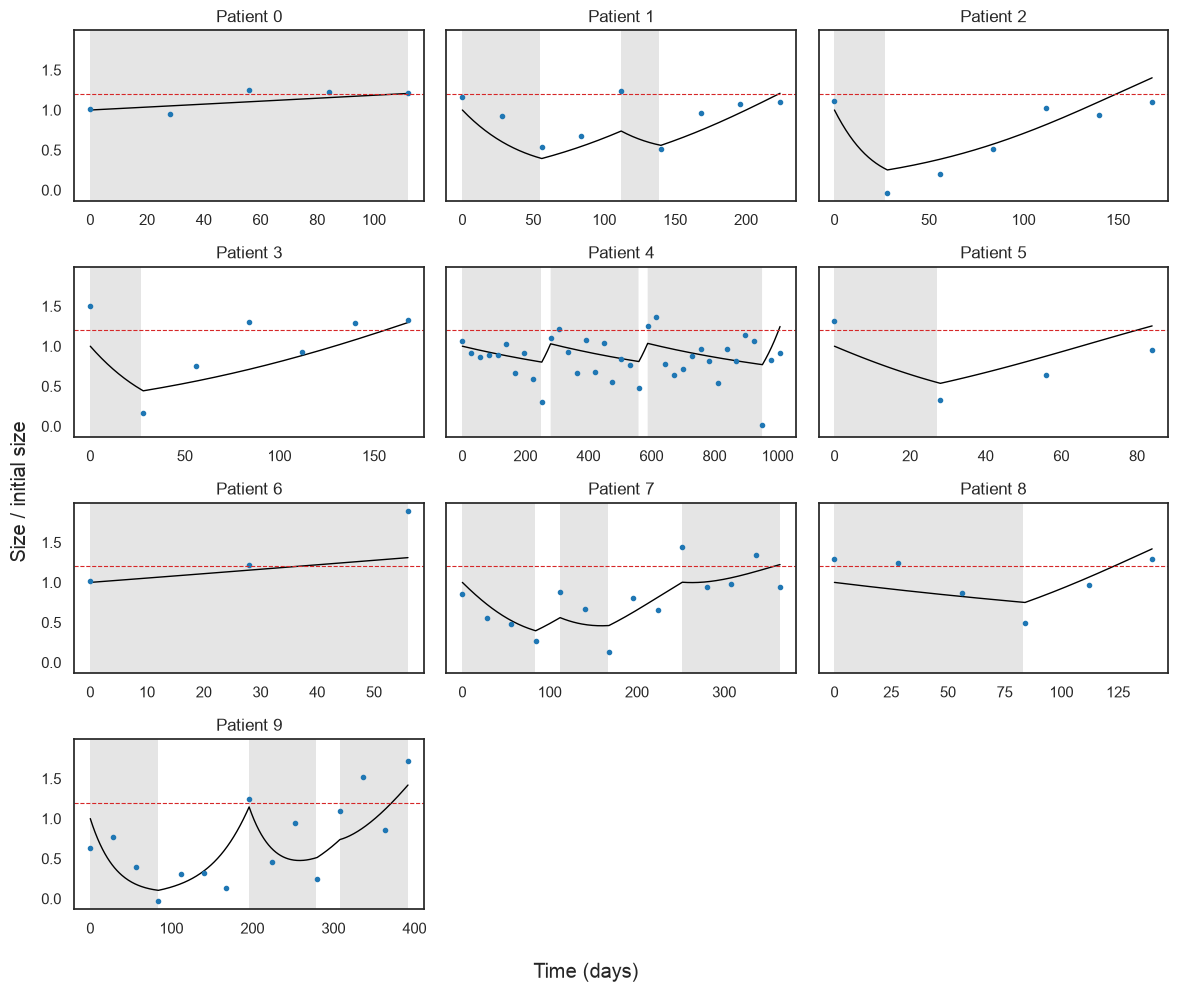

In [39]:
plot_n_rand_patients(synth_df, n=10);


### part 3
Fitig one of these using stan. setup model data

In [40]:
from utils.stan_data import to_stan_prior, make_stan_data, prior_init

patient_id = 4

synth_dir = Path('../synth_data_u')
synth_df = pd.read_csv(synth_dir / 'synth_patients.csv')
stan_model = cmdstanpy.CmdStanModel(stan_file='../stan/model_switchable_u.stan')
priors = {f"{k}_prior": to_stan_prior(d) for k, d in priorDic.items()}
stan_data = {**make_stan_data(synth_df, patient_id=patient_id, priors=priors), 'fit_u': 1, 'u_fixed_val': 0}

First we sample from priors only and compare priors put into the simulator

In [ ]:
#sample the prior with Stan and compare with priorDic
rng = np.random.default_rng(1)

#move to stan data file
def u_init():
    #redraw until u is below its upper bound 1 / n0
    while True:
        init = prior_init(priorDic, rng)
        if init['u_free'][0] * init['n0_free'][0] < 1:
            return init

#priorDic with the draws where u * n0 >= 1 removed, which is the prior Stan samples
ref = pd.DataFrame({k: d.rvs(100000, random_state=rng) for k, d in priorDic.items()})
ref = ref[ref['u'] * ref['n0'] < 1]

prior_fit = stan_model.sample(data=stan_data, chains=4, seed=1, inits=[u_init() for _ in range(4)], show_progress=False)
prior_draws = prior_fit.draws_pd(list(priorDic))

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (name, dist) in zip(axes.flat, priorDic.items()):
    ax.hist(prior_draws[name], bins=50, density=True, alpha=.5)
    ax.hist(ref[name], bins=50, density=True, histtype='step')
    ax.set_title(f"{name}")
axes.flat[-1].set_visible(False)
fig.tight_layout()

14:40:55 - cmdstanpy - INFO - CmdStan start processing
14:40:55 - cmdstanpy - INFO - Chain [1] start processing
14:40:55 - cmdstanpy - INFO - Chain [2] start processing
14:40:55 - cmdstanpy - INFO - Chain [3] start processing
14:40:55 - cmdstanpy - INFO - Chain [4] start processing


In [ ]:
truth = pd.read_csv(synth_dir / 'true_params.csv', index_col='PatientId').loc[patient_id]

#pathfinder inits: one approximate posterior draw per chain, started from a u_init() draw so u is below 1 / n0
pathfinder_fit = stan_model.pathfinder(data={**stan_data, 'prior_only': 0}, seed=1, inits=u_init())
pathfinder_inits = pathfinder_fit.create_inits(seed=1, chains=4)

#save_latent_dynamics: also write the unconstrained draws, used by the pair plot below
post_fit = stan_model.sample(data={**stan_data, 'prior_only': 0}, chains=4, seed=3, inits=pathfinder_inits,
                             adapt_delta=0.8, show_progress=True, save_latent_dynamics=True)
idata = az.from_cmdstanpy(posterior=post_fit)
print('divergences:', int(idata.sample_stats['diverging'].sum()))
print('P(u > 1.2):', float((idata.posterior['u'] > 1.2).mean()))
display(az.summary(idata, var_names=list(priorDic)))

post_draws = post_fit.draws_pd(list(priorDic))

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (name, dist) in zip(axes.flat, priorDic.items()):
    ax.hist(post_draws[name], bins=50, density=True, alpha=.5)
    ax.hist(ref[name], bins=50, density=True, histtype='step')
    ax.axvline(truth[name], color='black', ls='--')
    ax.set_title(name)
ax = axes.flat[-1]
ax.fill_between(stan_data['output_times'], *np.percentile(post_fit.stan_variable('PSA_pred'), [5, 95], axis=0), alpha=.3)
ax.plot(stan_data['output_times'], stan_data['PSA_norm'], 'o', ms=2, color='black')
ax.set_title(f'patient {patient_id}')
fig.tight_layout()

In [ ]:
#pair plot on the scale Stan samples on, read from Stan's diagnostic csv (one per chain), with the divergent draws marked
#columns are <name>_free.1 (and sigma); u_free is logit(u * n0), since u is bounded by 1 / n0
diag = [pd.read_csv(f, comment='#') for f in post_fit.runset.diagnostic_files]
unconstrained = idata.copy()
for name in priorDic:
    col = 'sigma' if name == 'sigma' else f'{name}_free.1'
    unconstrained['posterior'][name] = idata.posterior[name].copy(data=np.stack([d[col].to_numpy() for d in diag]))
az.rcParams['plot.max_subplots'] = 49  #7 parameters need 7 x 7 panels, the default limit is 40
az.plot_pair(idata, var_names=list(priorDic), visuals={'divergence': True});
az.plot_pair(unconstrained, var_names=list(priorDic), visuals={'divergence': True});

In [ ]:
# lets def a function to fit a single patient
def fit_patient(patient_id):
    synth_df = pd.read_csv(synth_dir / 'synth_patients.csv')
    patient_df = synth_df[synth_df['PatientId'] == patient_id]
    stan_data = {**make_stan_data(patient_df, patient_id=patient_id, priors=priors), 'fit_u': 1, 'u_fixed_val': 0}
    #pathfinder inits: one approximate posterior draw per chain, started from a u_init() draw so u is below 1 / n0
    pathfinder_fit = stan_model.pathfinder(data=stan_data, seed=4, inits=u_init())
    #keep every chain's draws (warmup too) on disk, so a hung or timed out chain still leaves its draws in the csv dir
    #save_latent_dynamics writes the diagnostic csv: unconstrained params, momenta (p_) and gradients (g_) per iteration
    post_fit = stan_model.sample(data=stan_data, chains=4, seed=4, inits=pathfinder_fit.create_inits(seed=4, chains=4),
                                 adapt_delta=0.8, show_progress=True, output_dir=out_dir / f'patient_{patient_id}_csv',
                                 save_warmup=True, save_latent_dynamics=True, timeout=300)
    idata = az.from_cmdstanpy(posterior=post_fit)
    #arviz keeps the warmup iterations in sample_stats (BUGS.md D24), keep only the sampling ones. warmup stays in the csv dir
    idata['sample_stats'] = idata.sample_stats.to_dataset().isel(draw=slice(-idata.posterior.sizes['draw'], None)).assign_coords(draw=idata.posterior.draw)
    return idata

#setup output dir
out_dir = Path('../synth_data_u/fits')
out_dir.mkdir(parents=True, exist_ok=True)
overwrite = True

errors = []

#fit patients
for patient_id in synth_df['PatientId'].unique():
    if (out_dir / f'patient_{patient_id}.nc').exists() and not overwrite:
        continue
    try:
        idata = fit_patient(patient_id)
        idata.to_netcdf(out_dir / f'patient_{patient_id}.nc') 
        print(f'Fitted patient {patient_id} out of {len(synth_df["PatientId"].unique())}')
    except Exception as e:
        #catch error and continue loop.
        errors.append(f'Patient {patient_id}: {e}') 
        continue


#save errors to file
with open(out_dir / 'errors.txt', 'w') as f:
    for error in errors:
        f.write(error + '\n')


In [ ]:
import arviz_stats as azs

#loop over files in fit folder
for path in sorted(Path('../synth_data_u/fits').glob('*.nc')):
    # read in fit
    idata = az.from_netcdf(path)
    # call arviz diagnose on fit
    problematic, diagnostics = azs.diagnose(idata, var_names=list(priorDic), show_diagnostics=False, return_diagnostics=True)
    if problematic: 
        print(f'{path.name}: {diagnostics}\n')

patient_4.nc: {'divergent': {'n_divergent': 1, 'pct': np.float64(0.025), 'total_samples': np.int64(4000)}, 'bfmi': {'bfmi_values': array([0.95378195, 0.87911916, 0.98173192, 0.89083995]), 'failed_chains': [], 'threshold': 0.3}, 'ess': {'bad_params': [], 'ess_values': <xarray.Dataset> Size: 0B
Dimensions:  ()
Data variables:
    *empty*, 'threshold_ratio': 0.001, 'total_samples': np.int64(4000)}, 'rhat': {'bad_params': [], 'rhat_values': <xarray.Dataset> Size: 0B
Dimensions:  ()
Data variables:
    *empty*, 'threshold': 1.01}}



In [ ]:
#unconstrained pair plot for every fit in the fit folder, on the scale Stan samples on, with the divergent draws marked
#unconstrained draws come from the diagnostic csvs fit_patient writes (columns <name>_free.1 and sigma; u_free is logit(u * n0))
fit_dir = Path('../synth_data_u/fits')
az.rcParams['plot.max_subplots'] = 49  #7 parameters need 7 x 7 panels, the default limit is 40
for path in sorted(fit_dir.glob('patient_*.nc'), key=lambda p: int(p.stem.split('_')[1])):
    idata = az.from_netcdf(path)
    n_draws = idata.posterior.sizes['draw']
    #diagnostic csvs of the latest run (timestamped names sort by run, then chain), sampling rows only (warmup was saved too)
    diag = [pd.read_csv(f, comment='#').tail(n_draws) for f in sorted((fit_dir / f'{path.stem}_csv').glob('*-diagnostic_*.csv'))[-4:]]
    unconstrained = idata.copy()
    for name in priorDic:
        col = 'sigma' if name == 'sigma' else f'{name}_free.1'
        unconstrained['posterior'][name] = idata.posterior[name].copy(data=np.stack([d[col].to_numpy() for d in diag]))
    #sample_stats in the .nc also holds the warmup iterations (first half), keep the sampling ones so divergences line up
    unconstrained['sample_stats'] = idata.sample_stats.to_dataset().isel(draw=slice(-n_draws, None)).assign_coords(draw=idata.posterior.draw)
    print(f'{path.stem}: {int(unconstrained.sample_stats["diverging"].sum())} divergences in sampling')
    az.plot_pair(unconstrained, var_names=list(priorDic), visuals={'divergence': True});